# 04B direct long tail

**Purpose.** Implement the authorized Phase 1 repair with preserved source values. Population: All 662,245 Direct rows; regression probability sample 150,000, seed 2026.

**Hypothesis.** Observable characteristics explain some but potentially little Direct slow-payment uncertainty; no causal mechanism is assumed.

**Methodology.** Full-population segment profiles at >300/>900/>1800 seconds, Wilson rate intervals, global Direct baselines and rate ratios. Currencies retain full codes in profiles and the top 20 currencies by Direct population frequency plus OTHER, without outcome screening in models. Transparent logistic GLMs include FX, currency group, log1p(USD), party, UTC hour/day and anomaly indicator. HC1 pointwise intervals assume independent rows. Five sample partitions test internal stability; development-to-validation and early-to-late predictions quantify residual log loss/Brier against training prevalence. All BIC profiles/coverage exported; sparse BIC dummies are excluded.

All duration calculations are seconds; rate differences are percentage points. Amount is USD-normalized. UNLABELED is not verified normal. Source placeholders, outliers and labels are retained. Private output tables can contain competition data and must not be committed or published.


In [1]:
from pathlib import Path
import sys
from IPython.display import display, Markdown, Image
ROOT = Path.cwd().resolve()
if not (ROOT / "data/cleaned/swift_payments_cleaned.csv").exists():
    ROOT = ROOT.parent
assert Path(sys.executable).resolve() == (ROOT / ".venv/Scripts/python.exe").resolve()
sys.path.insert(0, str(ROOT / "src"))
from phase1_analysis import Phase, direct_tail
phase = Phase(ROOT, '04B_direct_long_tail', 'duration/direct_tail')


## Code and evidence

The implementation is in `src/phase1_analysis.py`. All displayed values and exports are calculated; group denominators and support restrictions are included in each output table. Models are associational. Fixed sampling avoids repeated fitting on the entire text-heavy dataset; full-population descriptive evidence remains intact.


In [2]:
rates, coefficients_table, metrics = direct_tail(phase)
display(metrics)
display(coefficients_table.loc[coefficients_table.split.eq("full")])

Direct model 300 full 150000


Direct model 300 random_development 75375


Direct model 300 random_validation 74625


Direct model 300 chronological_early 75000


Direct model 300 chronological_late 75000


Direct model 900 full 150000


... (7 outputs left out)

Direct model 1800 chronological_early 75000


Direct model 1800 chronological_late 75000


,threshold_seconds,evaluation,fit_n,evaluation_n,events,observed_rate,log_loss,null_log_loss,remaining_log_loss_fraction,brier,null_brier,auc_descriptive,model_columns
0,300,full_in_sample,150000,150000,54732,0.364880,0.651074,0.656174,0.992227,0.229392,0.231743,0.557558,56
1,300,random_development_in_sample,75375,75375,27409,0.363635,0.649712,0.655481,0.991199,0.228753,0.231405,0.561111,56
2,300,random_validation_in_sample,74625,74625,27323,0.366137,0.652205,0.656868,0.992901,0.229927,0.232081,0.555143,56
3,300,chronological_early_in_sample,75000,75000,27362,0.364827,0.651390,0.656145,0.992753,0.229534,0.231728,0.555487,56
4,300,chronological_late_in_sample,75000,75000,27370,0.364933,0.650424,0.656204,0.991192,0.229098,0.231757,0.561207,56
5,300,random_development_to_random_validation,75375,74625,27323,0.366137,0.652694,0.656881,0.993625,0.230141,0.232087,0.553113,56
6,300,chronological_early_to_chronological_late,75000,75000,27370,0.364933,0.651095,0.656204,0.992215,0.229397,0.231757,0.558504,56
7,900,full_in_sample,150000,150000,37271,0.248473,0.553877,0.560652,0.987916,0.184209,0.186734,0.572600,56
8,900,random_development_in_sample,75375,75375,18665,0.247629,0.551985,0.559715,0.986190,0.183459,0.186309,0.577279,56
9,900,random_validation_in_sample,74625,74625,18606,0.249327,0.555454,0.561594,0.989066,0.184853,0.187163,0.570324,56


,feature,coefficient,ci_low,ci_high,p_value,split,outcome,model_n
0,Intercept,0.334578,0.198752,0.470404,1.379522e-06,full,IS_SLOW_300,150000
1,C(currency_group)[T.AUD],-0.850140,-0.981620,-0.718660,8.349602e-37,full,IS_SLOW_300,150000
2,C(currency_group)[T.CAD],-0.886057,-1.031488,-0.740626,7.202941e-33,full,IS_SLOW_300,150000
3,C(currency_group)[T.CHF],-0.833760,-0.942565,-0.724956,5.511088e-51,full,IS_SLOW_300,150000
4,C(currency_group)[T.CNY],-0.379352,-0.495955,-0.262749,1.811963e-10,full,IS_SLOW_300,150000
...,...,...,...,...,...,...,...,...
51,C(day)[T.5],-0.027779,-0.105535,0.049976,4.837875e-01,full,IS_SLOW_1800,150000
52,C(day)[T.6],-0.040656,-0.105462,0.024150,2.188491e-01,full,IS_SLOW_1800,150000
53,fx,-0.152812,-0.194268,-0.111356,5.021534e-13,full,IS_SLOW_1800,150000
54,log_amount,-0.008767,-0.015396,-0.002137,9.547140e-03,full,IS_SLOW_1800,150000


## Interpretation, limitations and business implications

Interpret only the estimated populations. Log-duration contrasts are not raw median changes; odds ratios are not risk ratios. Rate denominators are group-specific and slow thresholds are exploratory cut-offs, not Swift SLAs. Internal random and chronological checks are not external validation. Related payment families, residual bank/currency composition, coarse amount controls and sparse support limit causal interpretation. BIC outcome-overlap selection changes the estimand.

Use the evidence for source authority, supported segment monitoring and investigation priorities; no savings, fraud accuracy or operational improvement is inferred. An unexplained residual or insufficient common support is a valid result.


{
  "name": "04B_direct_long_tail",
  "run": "20261115T004348216639Z",
  "source_population": 1048575,
  "source_hashes": {
    "data\\cleaned\\swift_payments_cleaned.csv": "f8b2d946f647e02778d3b232be2f10a91f4adbf1b06c72045c075319a3a9d85c",
    "data\\raw\\swift_payments_raw_export.csv": "ea0eaa18311df2c9332aec336a198307df2996559f7f5abc2840ea0ef2d46d29",
    "data\\raw\\swift_umdac_datathon_2026_fictitious_payment_data.xlsx": "5787b5f9fee3ebcb8ab35462eab75931e70e77dc601c091f334d72dd9e32ea57"
  },
  "files": [
    "outputs\\tables\\duration\\direct_tail\\direct_segment_slow_rates.csv",
    "outputs\\tables\\duration\\direct_tail\\direct_bic_support_coverage.csv",
    "outputs\\tables\\duration\\direct_tail\\direct_adjusted_coefficients.csv",
    "outputs\\tables\\duration\\direct_tail\\direct_adjustment_residual_metrics.csv",
    "outputs\\tables\\duration\\direct_tail\\direct_model_design.csv",
    "outputs\\charts\\duration\\direct_tail\\direct_adjusted_effects.png",
    "outputs\\cha

## Final findings and limitations
Full segment populations retained; source Direct n=662245.

Internal holdout residuals: [{"threshold_seconds":300,"evaluation":"random_development_to_random_validation","fit_n":75375,"evaluation_n":74625,"events":27323,"observed_rate":0.3661373534,"log_loss":0.6526940864,"null_log_loss":0.6568813803,"remaining_log_loss_fraction":0.9936254946,"brier":0.2301410949,"null_brier":0.2320870528,"auc_descriptive":0.5531134605,"model_columns":56},{"threshold_seconds":300,"evaluation":"chronological_early_to_chronological_late","fit_n":75000,"evaluation_n":75000,"events":27370,"observed_rate":0.3649333333,"log_loss":0.6510951465,"null_log_loss":0.6562039704,"remaining_log_loss_fraction":0.9922145793,"brier":0.2293972357,"null_brier":0.2317570069,"auc_descriptive":0.5585043932,"model_columns":56},{"threshold_seconds":900,"evaluation":"random_development_to_random_validation","fit_n":75375,"evaluation_n":74625,"events":18606,"observed_rate":0.2493266332,"log_loss":0.5561278167,"null_log_loss":0.5616018926,"remaining_log_loss_fraction":0.9902527468,"brier":0.1850724322,"null_brier":0.1871657467,"auc_descriptive":0.566399333,"model_columns":56},{"threshold_seconds":900,"evaluation":"chronological_early_to_chronological_late","fit_n":75000,"evaluation_n":75000,"events":18572,"observed_rate":0.2476266667,"log_loss":0.5533041486,"null_log_loss":0.5597203909,"remaining_log_loss_fraction":0.9885367009,"brier":0.1839013369,"null_brier":0.186310568,"auc_descriptive":0.5695786553,"model_columns":56},{"threshold_seconds":1800,"evaluation":"random_development_to_random_validation","fit_n":75375,"evaluation_n":74625,"events":10849,"observed_rate":0.1453802345,"log_loss":0.4121750758,"null_log_loss":0.414612145,"remaining_log_loss_fraction":0.9941220506,"brier":0.1236197757,"null_brier":0.1242450505,"auc_descriptive":0.5560118316,"model_columns":56},{"threshold_seconds":1800,"evaluation":"chronological_early_to_chronological_late","fit_n":75000,"evaluation_n":75000,"events":10790,"observed_rate":0.1438666667,"log_loss":0.4089294763,"null_log_loss":0.4119470615,"remaining_log_loss_fraction":0.992674823,"brier":0.122436365,"null_brier":0.1231755344,"auc_descriptive":0.5603381116,"model_columns":56}]

Generated tables: `outputs\tables\duration\direct_tail`; charts: `outputs\charts\duration\direct_tail`. Source hashes and validation checks are in the completion manifest.

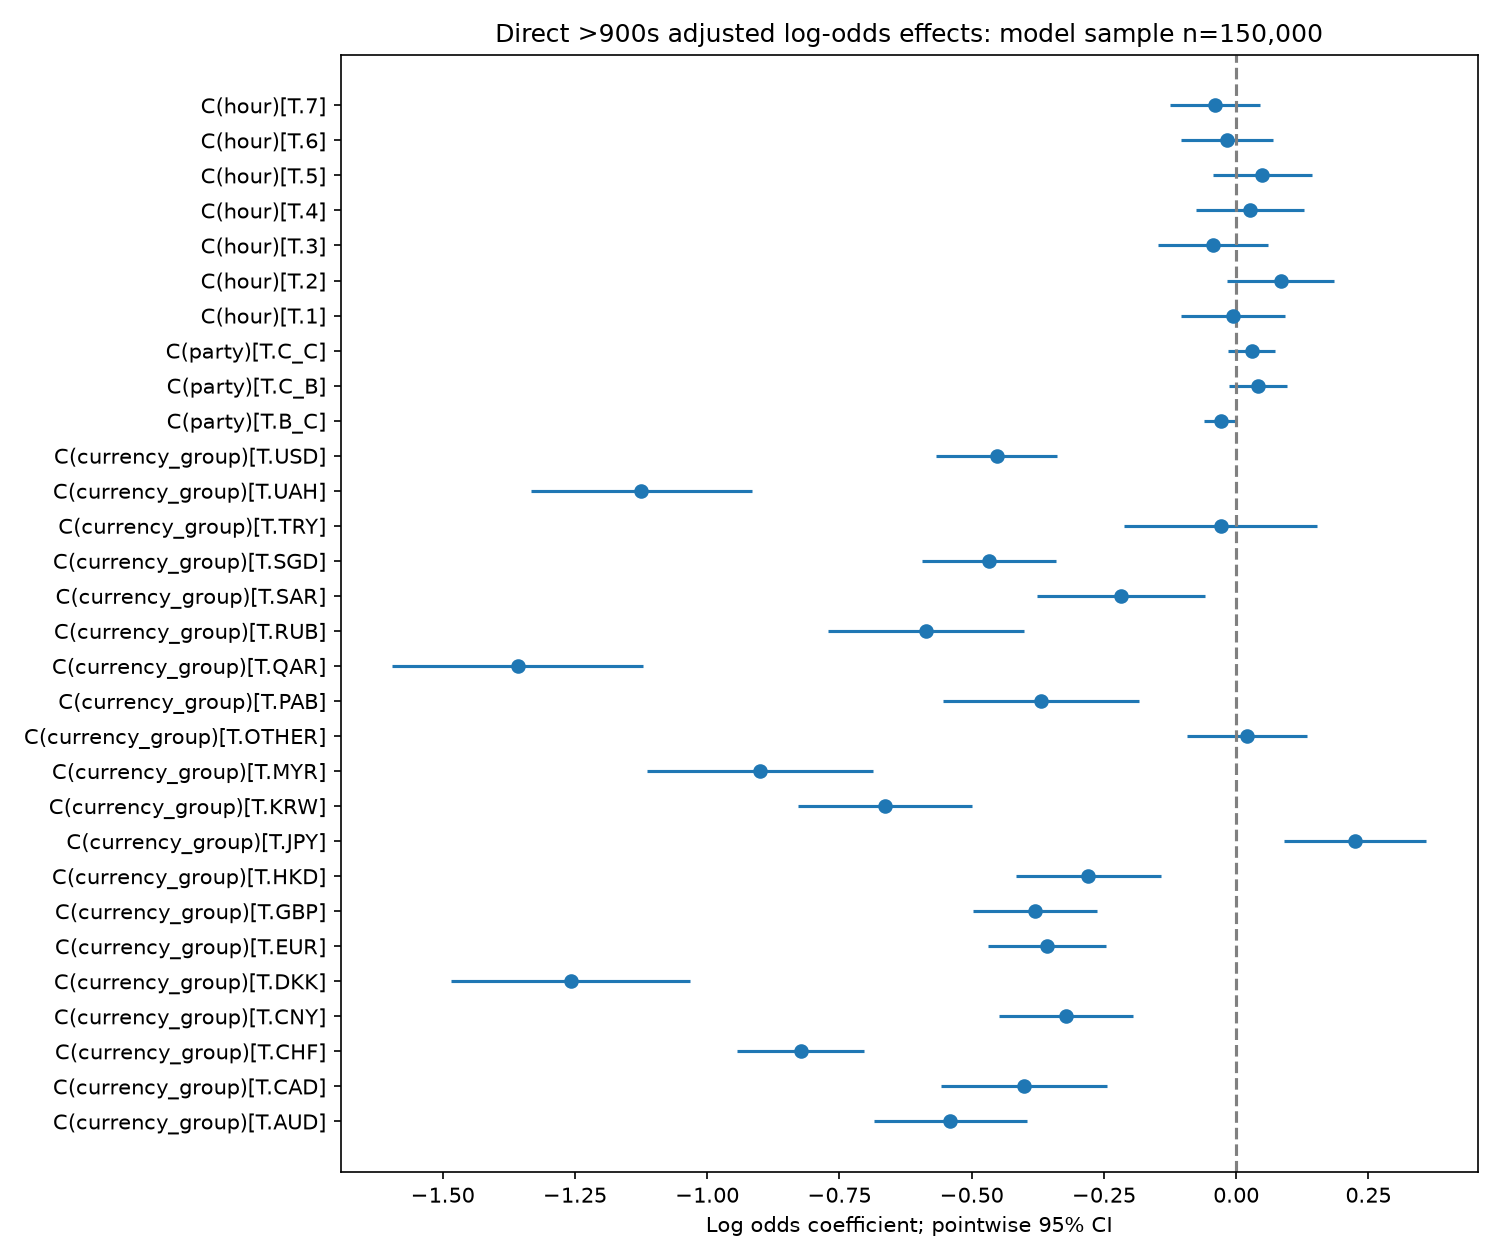

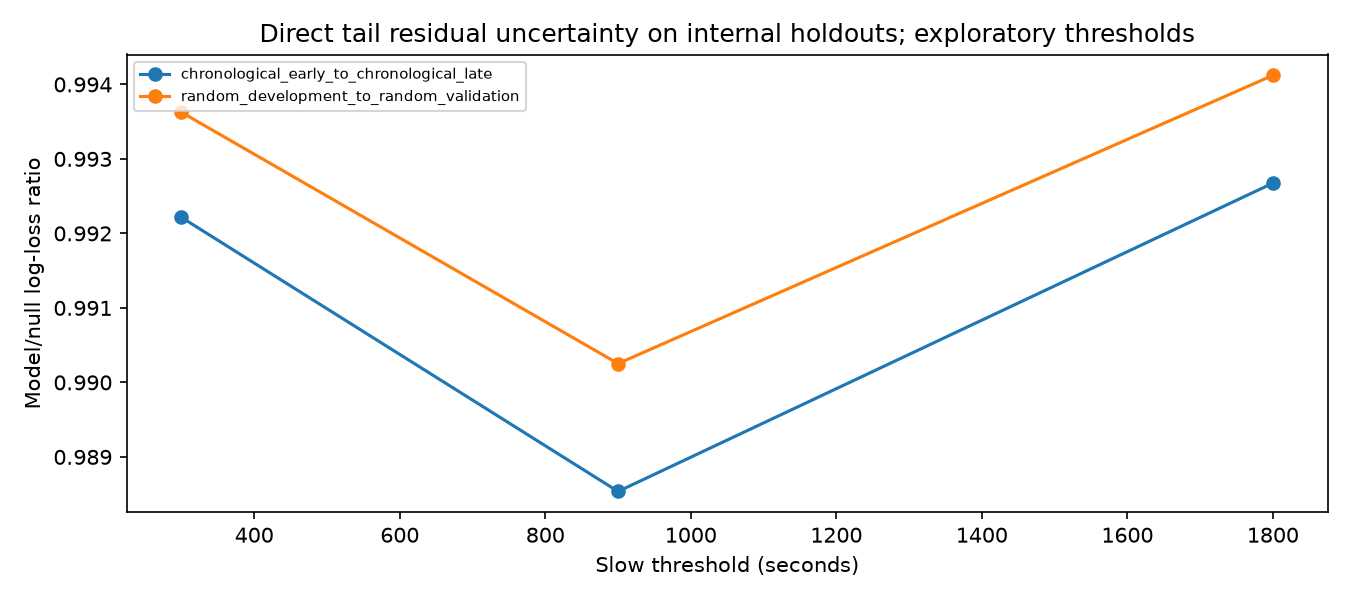

In [3]:
report = phase.finish(["Full segment populations retained; source Direct n=662245.", "Internal holdout residuals: " + metrics.loc[metrics.evaluation.str.contains("_to_")].to_json(orient="records")], ["Pointwise conditional uncertainty; no causal or external-validation claim.", "Restricted regression/common-support populations must not be generalized to the full network."])
display(Markdown("## Final findings and limitations\n" + "\n\n".join(report["findings"])))
display(Markdown("Generated tables: `" + str(phase.out.relative_to(ROOT)) + "`; charts: `" + str(phase.charts.relative_to(ROOT)) + "`. Source hashes and validation checks are in the completion manifest."))
for chart in sorted(phase.charts.glob("*.png")):
    display(Image(filename=str(chart)))
